In [83]:
import sys, sklearn, ipykernel
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
print(sys.version)
print(sys.executable)
print("Setup OK!")

print('test data cleaning')

print('hi')

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
c:\Users\kaanb\anaconda3\python.exe
Setup OK!
test data cleaning
hi


In [84]:
diabetic_data = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)
IDS_mapping = pd.read_csv('IDS_mapping.csv', na_values = ['?'], keep_default_na = False)

C:\Users\kaanb\AppData\Local\Temp\ipykernel_27744\2938591321.py:1: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  diabetic_data = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)


In [85]:
diabetic_data_1 = diabetic_data.drop(columns = ['discharge_disposition_id', 'encounter_id'])

In [86]:
diabetic_data_2 = diabetic_data_1.drop(columns = ['weight', 'payer_code', 'race'])
diabetic_data_2.shape

(101766, 45)

In [87]:
diabetic_data_3 = diabetic_data_2.drop(diabetic_data_2[diabetic_data_2['gender'] == 'Unknown/Invalid'].index)
diabetic_data_3.shape 

(101763, 45)

In [88]:
diabetic_data_3 = diabetic_data_3.drop(columns = ['examide', 'citoglipton'])
diabetic_data_3.shape

(101763, 43)

In [89]:
#Nateglinide
print(diabetic_data_3['nateglinide'].value_counts(normalize= True))

#chlorpropamide
print(diabetic_data_3['chlorpropamide'].value_counts(normalize=True)) #>99.9

#acetohexamide
print(diabetic_data_3['acetohexamide'].value_counts(normalize=True)) #>99.9

#tolbutamide
print(diabetic_data_3['tolbutamide'].value_counts(normalize=True)) #>99.9

#acarbose
print(diabetic_data_3['acarbose'].value_counts(normalize=True)) 

#miglitol
print(diabetic_data_3['miglitol'].value_counts(normalize=True)) #>99.9

#troglitazone
print(diabetic_data_3['troglitazone'].value_counts(normalize=True)) #99.9

#tolazamide
print(diabetic_data_3['tolazamide'].value_counts(normalize=True)) #>99.9

#glyburide-metformin
print(diabetic_data_3['glyburide-metformin'].value_counts(normalize=True))

#glipizide-metformin
print(diabetic_data_3['glipizide-metformin'].value_counts(normalize=True)) #>99.9

#glimepiride-pioglitazone
print(diabetic_data_3['glimepiride-pioglitazone'].value_counts(normalize=True)) #>99.9

#metformin-rosiglitazone
print(diabetic_data_3['metformin-rosiglitazone'].value_counts(normalize=True)) #>99.9

#metformin-pioglitazone
print(diabetic_data_3['metformin-pioglitazone'].value_counts(normalize=True)) #>99.9



nateglinide
No        0.993092
Steady    0.006564
Up        0.000236
Down      0.000108
Name: proportion, dtype: float64
chlorpropamide
No        0.999155
Steady    0.000776
Up        0.000059
Down      0.000010
Name: proportion, dtype: float64
acetohexamide
No        0.99999
Steady    0.00001
Name: proportion, dtype: float64
tolbutamide
No        0.999774
Steady    0.000226
Name: proportion, dtype: float64
acarbose
No        0.996973
Steady    0.002899
Up        0.000098
Down      0.000029
Name: proportion, dtype: float64
miglitol
No        0.999627
Steady    0.000305
Down      0.000049
Up        0.000020
Name: proportion, dtype: float64
troglitazone
No        0.999971
Steady    0.000029
Name: proportion, dtype: float64
tolazamide
No        0.999617
Steady    0.000373
Up        0.000010
Name: proportion, dtype: float64
glyburide-metformin
No        0.993062
Steady    0.006800
Up        0.000079
Down      0.000059
Name: proportion, dtype: float64
glipizide-metformin
No        0.999872


In [90]:
diabetic_data_4 = diabetic_data_3.drop(columns=['chlorpropamide', 'acetohexamide', 'tolbutamide',
 'miglitol', 'troglitazone','tolazamide', 'glipizide-metformin', 'glimepiride-pioglitazone','metformin-pioglitazone'    ])

diabetic_data_4.shape

(101763, 34)

In [91]:
#Dictionary for the descriptions of admission type id and admission source id
admission_type_descriptions = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective",
    4: "Newborn",
    5: "Not Available"
}

admission_source_descriptions = {
    1: "Physician Referral",
    2: "Emergency Room",
    3: "Transfer from Another Hospital",
    4: "Transfer from Skilled Nursing Facility",
    5: "Transfer from Psychiatric Hospital",
    6: "Transfer from Rehabilitation Center",
    7: "Not Available"
}

In [92]:
print(diabetic_data_4["age"].value_counts())
diabetic_data_4.groupby("age")["time_in_hospital"].mean()
young = diabetic_data_4[diabetic_data_4["age"] == "[0-10)"].copy()

print(young.shape)   
young                

age
[70-80)     26066
[60-70)     22482
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64
(161, 34)


,patient_nbr,gender,age,admission_type_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,glyburide,pioglitazone,rosiglitazone,acarbose,insulin,glyburide-metformin,metformin-rosiglitazone,change,diabetesMed,readmitted
0,8222157,Female,[0-10),6,1,1,Pediatrics-Endocrinology,41,0,1,...,No,No,No,No,No,No,No,No,No,NO
216,2359485,Female,[0-10),6,7,3,Pediatrics-Endocrinology,34,0,4,...,No,No,No,No,Steady,No,No,No,Yes,NO
270,8568180,Female,[0-10),6,7,2,Pediatrics-Endocrinology,45,0,5,...,No,No,No,No,Steady,No,No,No,Yes,NO
294,5832918,Female,[0-10),6,7,1,Pediatrics-CriticalCare,54,0,8,...,No,No,No,No,Steady,No,No,No,Yes,>30
474,7443135,Female,[0-10),6,7,2,Pediatrics,11,0,11,...,No,No,No,No,Steady,No,No,No,Yes,NO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
89538,42247008,Male,[0-10),3,1,2,NaN,1,0,3,...,No,No,No,No,Up,No,No,Ch,Yes,NO
89636,44988678,Male,[0-10),1,7,2,NaN,58,0,8,...,No,No,No,No,No,No,No,No,No,NO
93803,42347718,Male,[0-10),3,1,1,Pediatrics,20,0,1,...,No,No,No,No,No,No,No,No,No,NO
98900,110172294,Female,[0-10),1,7,1,NaN,63,1,14,...,No,No,No,No,No,No,No,No,No,NO


In [93]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
female = diabetic_data_4[diabetic_data_4['gender'] == 'Female'].copy()

female.info

gender
Female    54708
Male      47055
Name: count, dtype: int64


<bound method DataFrame.info of         patient_nbr  gender       age  admission_type_id  admission_source_id  \
0           8222157  Female    [0-10)                  6                    1   
1          55629189  Female   [10-20)                  1                    7   
2          86047875  Female   [20-30)                  1                    7   
8          48330783  Female   [80-90)                  2                    4   
9          63555939  Female  [90-100)                  3                    4   
...             ...     ...       ...                ...                  ...   
101757    181593374  Female   [70-80)                  1                    7   
101758    120975314  Female   [80-90)                  1                    7   
101760     50375628  Female   [60-70)                  1                    7   
101762     74694222  Female   [80-90)                  1                    5   
101764     31693671  Female   [80-90)                  2                    7

In [94]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
male = diabetic_data_4[diabetic_data_4['gender'] == 'Male'].copy()

male.info

gender
Female    54708
Male      47055
Name: count, dtype: int64


<bound method DataFrame.info of         patient_nbr gender      age  admission_type_id  admission_source_id  \
3          82442376   Male  [30-40)                  1                    7   
4          42519267   Male  [40-50)                  1                    7   
5          82637451   Male  [50-60)                  2                    2   
6          84259809   Male  [60-70)                  3                    2   
7         114882984   Male  [70-80)                  1                    7   
...             ...    ...      ...                ...                  ...   
101753    184875899   Male  [40-50)                  1                    7   
101759     86472243   Male  [80-90)                  1                    7   
101761    100162476   Male  [70-80)                  1                    7   
101763     41088789   Male  [70-80)                  1                    7   
101765    175429310   Male  [70-80)                  1                    7   

        time_in_hos

In [95]:
#Admission type id -> Time in hospital
admission_type_means = diabetic_data_4.groupby(['admission_type_id'])['time_in_hospital'].mean()

#Admissionn source id -> Time in hospital
admission_source_means = diabetic_data_4.groupby(['admission_source_id'])['time_in_hospital'].mean()

#Replacing the admission type id and admission source id with their descriptions
admission_type_means.index = admission_type_means.index.map(admission_type_descriptions)
admission_source_means.index = admission_source_means.index.map(admission_source_descriptions)

print(admission_type_means)
print(admission_source_means)

#Grouping admission type id with admission source id
admission_type_source_means = diabetic_data_4.groupby(['admission_type_id', 'admission_source_id'])['time_in_hospital'].mean()
admission_type_source_means.index = admission_type_source_means.index.map(lambda x: (admission_type_descriptions.get(x[0]), admission_source_descriptions.get(x[1])))

print(admission_type_source_means)


admission_type_id
Emergency        4.378269
Urgent           4.610714
Elective         4.320649
Newborn          3.200000
Not Available    3.947126
NaN              4.583066
NaN              4.857143
NaN              3.062500
Name: time_in_hospital, dtype: float64
admission_source_id
Physician Referral                         4.257915
Emergency Room                             4.684783
Transfer from Another Hospital             4.823529
Transfer from Skilled Nursing Facility     5.814559
Transfer from Psychiatric Hospital         5.829240
Transfer from Rehabilitation Center        4.426237
Not Available                              4.387515
NaN                                        5.562500
NaN                                        3.416000
NaN                                        4.375000
NaN                                        2.500000
NaN                                        3.000000
NaN                                        3.000000
NaN                                    

In [96]:
#ANOVA test to see what factors have a significant effect on the time in hospital
import statsmodels.api as sm

model = sm.OLS(diabetic_data_2['time_in_hospital'], sm.add_constant(diabetic_data_2[['admission_type_id', 'admission_source_id']])).fit()

print(model.summary())

#Determining significant factors based on p-values
significant_factors = model.pvalues[model.pvalues < 0.05].index
print(significant_factors)


                            OLS Regression Results                            
Dep. Variable:       time_in_hospital   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     9.584
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           6.89e-05
Time:                        15:37:27   Log-Likelihood:            -2.5568e+05
No. Observations:              101766   AIC:                         5.114e+05
Df Residuals:                  101763   BIC:                         5.114e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   4.4698    

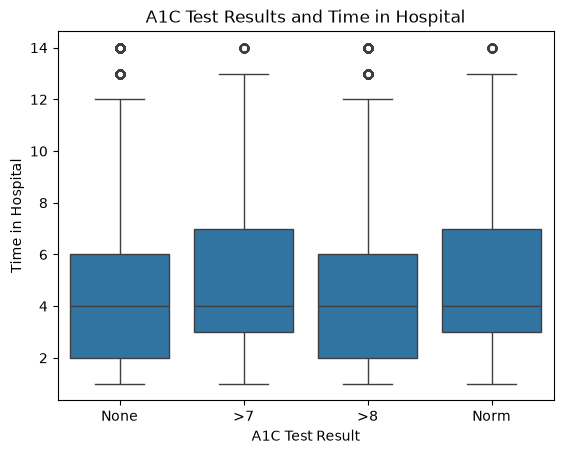

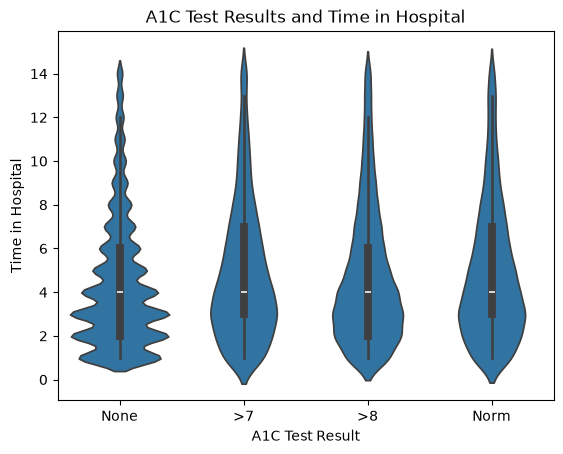

In [102]:
#Generating a plot for A1C tests and time in hospital
sns.boxplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')

#Generating a violin plot
plt.figure()
sns.violinplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')
plt.show()

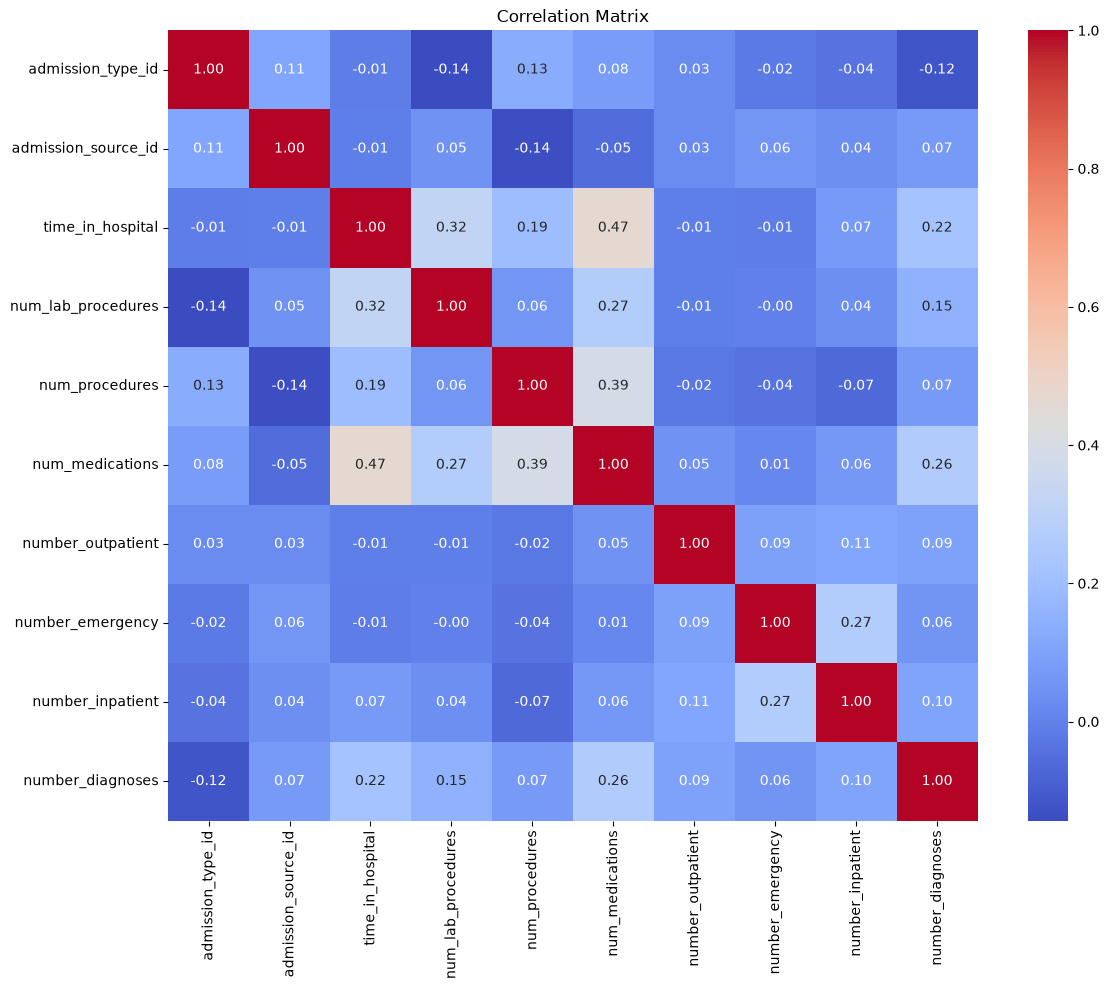

In [105]:
#Correlation Matrix
plt.figure(figsize=(12,10))
numeric_data = diabetic_data_4.select_dtypes(include='number').drop(columns='patient_nbr', errors='ignore')
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')


In [ ]:
numerical_columns = diabetic_data_4.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numerical_columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=diabetic_data_4[col])

